In [1]:
# ============================================================
# IMPORTS
# ============================================================

import itertools
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

In [2]:
# ============================================================
# NOTEBOOK CONFIGURATION
# ============================================================

from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility"
)

DATA_DIR = PROJECT_DIR / "processed_data_final"
OUTPUT_DIR = DATA_DIR / "idm_core_runs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Main IDM core notebook uses the braking-sensitive asymmetric definition
BRAKE_THRESHOLD = -0.1
ACCEL_THRESHOLD = 0.2

THRESHOLD_TAG = f"brake{abs(BRAKE_THRESHOLD):.1f}_accel{ACCEL_THRESHOLD:.1f}".replace(".", "p")
RUN_DIR = OUTPUT_DIR / f"idm_core_{THRESHOLD_TAG}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

print("Using regime definition:")
print(f"braking      : a_true < {BRAKE_THRESHOLD}")
print(f"accelerating : a_true > {ACCEL_THRESHOLD}")
print("steady       : otherwise")
print("Data dir     :", DATA_DIR)
print("Run dir      :", RUN_DIR)


# ============================================================
# HORIZON CONFIG
# ============================================================

FPS = 25
HISTORY = 25
HORIZON = 75      # change this to 13, 25, 50, 75, or 125
STRIDE = 1

HORIZON_SECONDS = HORIZON / FPS
HORIZON_TAG = f"H{HISTORY}_Hz{HORIZON}_S{STRIDE}"

print("Horizon frames:", HORIZON)
print("Horizon seconds:", HORIZON_SECONDS)
print("Horizon tag:", HORIZON_TAG)

Using regime definition:
braking      : a_true < -0.1
accelerating : a_true > 0.2
steady       : otherwise
Data dir     : C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final
Run dir      : C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_brake0p1_accel0p2
Horizon frames: 75
Horizon seconds: 3.0
Horizon tag: H25_Hz75_S1


# Import Cleaned Data

In [3]:
required_files = [
    DATA_DIR / "episode_tracks_train.csv",
    DATA_DIR / "episode_tracks_val.csv",
    DATA_DIR / "episode_tracks_test.csv",
]

for p in required_files:
    assert p.exists(), f"Missing required file: {p}"

episode_tracks_train = pd.read_csv(DATA_DIR / "episode_tracks_train.csv")
episode_tracks_val   = pd.read_csv(DATA_DIR / "episode_tracks_val.csv")
episode_tracks_test  = pd.read_csv(DATA_DIR / "episode_tracks_test.csv")

print("\n=== SPLIT CHECKS ===")
print("Train split values:")
print(episode_tracks_train["split"].value_counts())

print("\nVal split values:")
print(episode_tracks_val["split"].value_counts())

print("\nTest split values:")
print(episode_tracks_test["split"].value_counts())

print("\nTrain egos:", episode_tracks_train["unique_id"].nunique())
print("Val egos:", episode_tracks_val["unique_id"].nunique())
print("Test egos:", episode_tracks_test["unique_id"].nunique())

print("\nTrain episodes:", episode_tracks_train["episode_id"].nunique())
print("Val episodes:", episode_tracks_val["episode_id"].nunique())
print("Test episodes:", episode_tracks_test["episode_id"].nunique())


=== SPLIT CHECKS ===
Train split values:
split
train    11094352
Name: count, dtype: int64

Val split values:
split
val    2370107
Name: count, dtype: int64

Test split values:
split
test    2368174
Name: count, dtype: int64

Train egos: 34862
Val egos: 7470
Test egos: 7471

Train episodes: 34870
Val episodes: 7470
Test episodes: 7471


In [4]:
# ============================================================
# DEFINE IDM DATA FOR ORIGINAL SPLIT CALIBRATION
# ============================================================

keep_cols = [
    "recording_id",
    "unique_id",
    "frame",
    "id",
    "precedingId",
    "preceding_unique_id",
    "laneId",
    "xVelocity",
    "precedingXVelocity",
    "dhw",
    "xAcceleration",
    "episode_id",
    "split"
]

idm_train = episode_tracks_train[keep_cols].copy()
idm_val   = episode_tracks_val[keep_cols].copy()
idm_test  = episode_tracks_test[keep_cols].copy()

print("\n=== IDM DATA USED IN THIS NOTEBOOK ===")
print("idm_train:", idm_train.shape)
print("idm_val  :", idm_val.shape)
print("idm_test :", idm_test.shape)

print("\nUnique egos:")
print("idm_train:", idm_train["unique_id"].nunique())
print("idm_val  :", idm_val["unique_id"].nunique())
print("idm_test :", idm_test["unique_id"].nunique())

print("\nUnique episodes:")
print("idm_train:", idm_train["episode_id"].nunique())
print("idm_val  :", idm_val["episode_id"].nunique())
print("idm_test :", idm_test["episode_id"].nunique())


=== IDM DATA USED IN THIS NOTEBOOK ===
idm_train: (11094352, 13)
idm_val  : (2370107, 13)
idm_test : (2368174, 13)

Unique egos:
idm_train: 34862
idm_val  : 7470
idm_test : 7471

Unique episodes:
idm_train: 34870
idm_val  : 7470
idm_test : 7471


In [5]:
# ============================================================
# ALIGN IDM DATA TO THE SAME TARGET ROWS AS THE TRANSFORMER
#
# Transformer:
#   history window = frames [start, ..., start + HISTORY - 1]
#   current state  = frame  start + HISTORY - 1
#   target         = current state + HORIZON
#
# This produces exactly:
#   n_frames - HISTORY - HORIZON + 1
# rows per episode when STRIDE = 1.
# ============================================================

def make_horizon_aligned_idm_df(
    df,
    history,
    horizon,
    stride=1,
):
    aligned_parts = []

    minimum_length = history + horizon

    for episode_id, g in df.groupby("episode_id", sort=False):
        g = g.sort_values("frame").reset_index(drop=True)

        if len(g) < minimum_length:
            continue

        # The IDM receives the traffic state at the final frame
        # of the Transformer's history window.
        input_start = history - 1
        input_stop = len(g) - horizon

        input_indices = np.arange(
            input_start,
            input_stop,
            stride,
            dtype=int,
        )

        target_indices = input_indices + horizon

        input_rows = g.iloc[input_indices].copy().reset_index(drop=True)
        target_rows = g.iloc[target_indices].copy().reset_index(drop=True)

        # Frames used for verification
        input_rows["input_frame"] = g.iloc[input_indices]["frame"].to_numpy()
        input_rows["target_frame"] = g.iloc[target_indices]["frame"].to_numpy()

        # Future acceleration target
        if "a_true" in target_rows.columns:
            input_rows["a_true"] = target_rows["a_true"].to_numpy()
        else:
            input_rows["a_true"] = target_rows["xAcceleration"].to_numpy()

        # Regime is determined from future acceleration
        input_rows["true_regime"] = np.select(
            [
                input_rows["a_true"] < BRAKE_THRESHOLD,
                input_rows["a_true"] > ACCEL_THRESHOLD,
            ],
            [
                "braking",
                "accelerating",
            ],
            default="steady",
        )

        input_rows["history_frames"] = history
        input_rows["horizon_frames"] = horizon
        input_rows["horizon_seconds"] = horizon / FPS
        input_rows["stride"] = stride

        aligned_parts.append(input_rows)

    if not aligned_parts:
        return pd.DataFrame()

    return pd.concat(aligned_parts, ignore_index=True)


idm_train_h = make_horizon_aligned_idm_df(
    idm_train,
    history=HISTORY,
    horizon=HORIZON,
    stride=STRIDE,
)

idm_val_h = make_horizon_aligned_idm_df(
    idm_val,
    history=HISTORY,
    horizon=HORIZON,
    stride=STRIDE,
)

idm_test_h = make_horizon_aligned_idm_df(
    idm_test,
    history=HISTORY,
    horizon=HORIZON,
    stride=STRIDE,
)


print("=== TRANSFORMER-ALIGNED IDM DATA ===")
print(f"History: {HISTORY} frames = {HISTORY / FPS:.2f} s")
print(f"Horizon: {HORIZON} frames = {HORIZON / FPS:.2f} s")
print("Stride:", STRIDE)

print("\nRows:")
print("Train:", len(idm_train_h))
print("Val:  ", len(idm_val_h))
print("Test: ", len(idm_test_h))

print("\nTarget-frame difference:")
print(
    (
        idm_test_h["target_frame"]
        - idm_test_h["input_frame"]
    ).describe()
)

print("\nTest regime counts:")
print(idm_test_h["true_regime"].value_counts())

=== TRANSFORMER-ALIGNED IDM DATA ===
History: 25 frames = 1.00 s
Horizon: 75 frames = 3.00 s
Stride: 1

Rows:
Train: 7642222
Val:   1630577
Test:  1628545

Target-frame difference:
count    1628545.0
mean          75.0
std            0.0
min           75.0
25%           75.0
50%           75.0
75%           75.0
max           75.0
dtype: float64

Test regime counts:
true_regime
steady          848187
accelerating    454352
braking         326006
Name: count, dtype: int64


In [6]:
# ============================================================
# SPLIT INTEGRITY CHECKS
# ============================================================

all_data = pd.concat([
    idm_train.assign(split_source="train"),
    idm_val.assign(split_source="val"),
    idm_test.assign(split_source="test")
], axis=0)

ego_split_check = all_data.groupby("unique_id")["split_source"].nunique()
episode_split_check = all_data.groupby("episode_id")["split_source"].nunique()

print("\n=== SPLIT INTEGRITY CHECKS ===")
print("Egos in multiple splits:", int((ego_split_check > 1).sum()))
print("Episodes in multiple splits:", int((episode_split_check > 1).sum()))

print("\nRows by split:")
print(all_data["split_source"].value_counts().to_string())

assert (ego_split_check <= 1).all(), "Some ego vehicles appear in multiple splits."
assert (episode_split_check <= 1).all(), "Some episodes appear in multiple splits."

print("\nSplit integrity checks passed.")


=== SPLIT INTEGRITY CHECKS ===
Egos in multiple splits: 0
Episodes in multiple splits: 0

Rows by split:
split_source
train    11094352
val       2370107
test      2368174

Split integrity checks passed.


## IDM Equation

In [7]:
# ============================================================
# IDM ACCELERATION FUNCTION
# Memory-safe version
# ============================================================

def idm_acceleration(v, delta_v, s, params):
    v0 = max(float(params["v0"]), 1e-6)
    T = float(params["T"])
    a = max(float(params["a"]), 1e-6)
    b = max(float(params["b"]), 1e-6)
    s0 = float(params["s0"])
    delta = float(params["delta"])

    v = np.asarray(v, dtype=np.float32)
    delta_v = np.asarray(delta_v, dtype=np.float32)
    s = np.asarray(s, dtype=np.float32)

    v = np.maximum(v, 0.0)
    s = np.maximum(s, 0.1)

    sqrt_ab = np.sqrt(a * b)

    s_star = s0 + np.maximum(
        0.0,
        v * T + (v * delta_v) / (2.0 * sqrt_ab)
    )

    acc = a * (1.0 - (v / v0) ** delta - (s_star / s) ** 2)

    return acc.astype(np.float32)

# Evaluate Baseline

In [8]:

def prepare_idm_features(df):
    out = df.copy()

    # Core variables
    out["v_ego"] = out["xVelocity"].abs()
    out["v_leader"] = out["precedingXVelocity"].abs()
    
    if "a_true" not in out.columns:
        out["a_true"] = out["xAcceleration"]

    # Detect no-leader cases robustly
    no_leader = (
        out["precedingId"].isna()
        | (out["precedingId"] <= 0)
        | out["precedingXVelocity"].isna()
        | out["dhw"].isna()
    )

    # Relative speed and gap
    out["delta_v"] = out["v_ego"] - out["v_leader"]
    out["gap"] = out["dhw"].clip(lower=0.1)

    # Enforce thesis rule for no-leader
    out.loc[no_leader, "gap"] = 1e6
    out.loc[no_leader, "delta_v"] = 0.0
    out.loc[no_leader, "v_leader"] = out.loc[no_leader, "v_ego"]

    out["no_leader"] = no_leader.astype(int)
    return out

def add_regime_column(df, true_col="a_true"):
    out = df.copy()
    out["regime"] = np.where(
        out[true_col] < BRAKE_THRESHOLD, "braking",
        np.where(out[true_col] > ACCEL_THRESHOLD, "accelerating", "steady")
    )
    return out

def compute_regime_metrics(df, pred_col="a_idm", true_col="a_true"):
    temp = add_regime_column(df, true_col=true_col)

    regime_metrics = (
        temp.groupby("regime")
        .apply(lambda g: pd.Series({
            "MAE": np.mean(np.abs(g[true_col] - g[pred_col])),
            "RMSE": np.sqrt(np.mean((g[true_col] - g[pred_col]) ** 2)),
            "Bias": np.mean(g[pred_col] - g[true_col]),
            "Count": len(g)
        }))
        .reset_index()
    )

    regime_map = {
        row["regime"]: {
            "MAE": row["MAE"],
            "RMSE": row["RMSE"],
            "Bias": row["Bias"],
            "Count": row["Count"]
        }
        for _, row in regime_metrics.iterrows()
    }

    return regime_metrics, regime_map

def evaluate_idm(df, params):
    out = prepare_idm_features(df)

    # IDM prediction
    out["a_idm_raw"] = idm_acceleration(
        v=out["v_ego"],
        delta_v=out["delta_v"],
        s=out["gap"],
        params=params
    )

    # Physical plausibility clipping
    out["a_idm"] = out["a_idm_raw"].clip(-8, 4)

    # Global metrics
    mae = mean_absolute_error(out["a_true"], out["a_idm"])
    rmse = np.sqrt(mean_squared_error(out["a_true"], out["a_idm"]))
    medae = median_absolute_error(out["a_true"], out["a_idm"])
    r2 = r2_score(out["a_true"], out["a_idm"])
    bias = (out["a_idm"] - out["a_true"]).mean()
    corr = out["a_true"].corr(out["a_idm"])
    clip_fraction = ((out["a_idm"] <= -8) | (out["a_idm"] >= 4)).mean()

    metrics = {
        "MAE": mae,
        "RMSE": rmse,
        "MedAE": medae,
        "R2": r2,
        "Bias": bias,
        "Corr": corr,
        "ClipFrac": clip_fraction
    }

    return out, metrics

In [9]:
# ============================================================
# LIGHTWEIGHT IDM METRICS FOR GRID SEARCH
# Avoids copying full dataframe for every parameter combination.
# ============================================================

def make_idm_arrays(df):
    """
    Convert a dataframe into compact NumPy arrays once.
    Used for fast/memory-safe grid search.
    """

    v_ego = df["xVelocity"].abs().to_numpy(dtype=np.float32)
    v_leader = df["precedingXVelocity"].abs().to_numpy(dtype=np.float32)
    a_true = df["a_true"].to_numpy(dtype=np.float32)

    preceding_id = df["precedingId"].to_numpy()
    dhw = df["dhw"].to_numpy(dtype=np.float32)
    preceding_xv = df["precedingXVelocity"].to_numpy(dtype=np.float32)

    no_leader = (
        pd.isna(preceding_id)
        | (preceding_id <= 0)
        | np.isnan(preceding_xv)
        | np.isnan(dhw)
    )

    delta_v = v_ego - v_leader
    gap = np.maximum(dhw, 0.1).astype(np.float32)

    # Free-road convention for auxiliary IDM stability
    gap[no_leader] = 1e6
    delta_v[no_leader] = 0.0
    v_leader[no_leader] = v_ego[no_leader]

    return {
        "v_ego": v_ego,
        "delta_v": delta_v,
        "gap": gap,
        "a_true": a_true,
    }


def evaluate_idm_arrays(arrays, params):
    """
    Fast IDM evaluation for grid search.
    Returns metrics only, not a scored dataframe.
    """

    a_pred_raw = idm_acceleration(
        v=arrays["v_ego"],
        delta_v=arrays["delta_v"],
        s=arrays["gap"],
        params=params
    )

    a_pred = np.clip(a_pred_raw, -8, 4).astype(np.float32)
    a_true = arrays["a_true"]

    err = a_pred - a_true
    abs_err = np.abs(err)

    mae = float(np.mean(abs_err))
    rmse = float(np.sqrt(np.mean(err ** 2)))
    medae = float(np.median(abs_err))
    bias = float(np.mean(err))

    ss_res = float(np.sum(err ** 2))
    ss_tot = float(np.sum((a_true - np.mean(a_true)) ** 2))
    r2 = float(1.0 - ss_res / ss_tot) if ss_tot > 0 else np.nan

    if np.std(a_true) > 0 and np.std(a_pred) > 0:
        corr = float(np.corrcoef(a_true, a_pred)[0, 1])
    else:
        corr = np.nan

    clip_fraction = float(np.mean((a_pred <= -8) | (a_pred >= 4)))

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MedAE": medae,
        "R2": r2,
        "Bias": bias,
        "Corr": corr,
        "ClipFrac": clip_fraction,
    }

In [10]:
# ============================================================
# GLOBAL IDM PARAMETER GRID
# Used by the global IDM grid search cell below
# ============================================================

param_grid = {
    "v0": [38.0, 40.0, 42.0, 44.0],
    #"v0": [34.0, 36.0, 38.0, 40.0],
    "T": [0.5, 0.6, 0.7, 0.8],
    "s0": [0.5, 0.75, 1.0, 1.25],
    "a": [0.4, 0.6, 0.8, 1.0],
    "b": [3.5, 4.0, 4.5, 5.0],
    "delta": [4]
}
print("Global IDM parameter grid ready.")
print("Total combinations:",
      len(param_grid["v0"])
      * len(param_grid["T"])
      * len(param_grid["s0"])
      * len(param_grid["a"])
      * len(param_grid["b"])
      * len(param_grid["delta"]))

Global IDM parameter grid ready.
Total combinations: 1024


## Global IDM Calibration

The first stage of the analysis calibrates a single global IDM parameter set using the training and validation splits. This serves as the classical baseline against which the regime-specific and piecewise IDM extensions are compared.

In [11]:
# ============================================================
# GRID SEARCH ON TRAIN / VALIDATION
# Cached global IDM grid search
# ============================================================

global_grid_path = RUN_DIR / f"idm_global_grid_search_{HORIZON_TAG}.csv"

if global_grid_path.exists():
    print("Loading existing global grid search:")
    print(global_grid_path)

    grid_results = pd.read_csv(global_grid_path)

else:
    print("Running global IDM grid search...")

    results = []

    all_combinations = list(itertools.product(
        param_grid["v0"],
        param_grid["T"],
        param_grid["s0"],
        param_grid["a"],
        param_grid["b"],
        param_grid["delta"]
    ))

    print("Total combinations:", len(all_combinations))

    # Use compact arrays to avoid copying full dataframes repeatedly
    print("Preparing compact train/val arrays...")
    train_arrays = make_idm_arrays(idm_train_h)
    val_arrays = make_idm_arrays(idm_val_h)

    for i, (v0, T, s0, a, b, delta) in enumerate(all_combinations, start=1):
        params = {
            "v0": v0,
            "T": T,
            "s0": s0,
            "a": a,
            "b": b,
            "delta": delta
        }

        train_metrics = evaluate_idm_arrays(train_arrays, params)
        val_metrics = evaluate_idm_arrays(val_arrays, params)

        results.append({
            "v0": v0,
            "T": T,
            "s0": s0,
            "a": a,
            "b": b,
            "delta": delta,

            "mae_train": train_metrics["MAE"],
            "rmse_train": train_metrics["RMSE"],
            "medae_train": train_metrics["MedAE"],
            "r2_train": train_metrics["R2"],
            "bias_train": train_metrics["Bias"],
            "corr_train": train_metrics["Corr"],
            "clipfrac_train": train_metrics["ClipFrac"],

            "mae_val": val_metrics["MAE"],
            "rmse_val": val_metrics["RMSE"],
            "medae_val": val_metrics["MedAE"],
            "r2_val": val_metrics["R2"],
            "bias_val": val_metrics["Bias"],
            "corr_val": val_metrics["Corr"],
            "clipfrac_val": val_metrics["ClipFrac"],
        })

        if i % 50 == 0 or i == len(all_combinations):
            print(f"Processed {i}/{len(all_combinations)}")

    grid_results = (
        pd.DataFrame(results)
        .sort_values(
            by=["mae_val", "rmse_val", "mae_train"],
            ascending=[True, True, True]
        )
        .reset_index(drop=True)
    )

    grid_results.to_csv(global_grid_path, index=False)

    print("Saved global grid search to:")
    print(global_grid_path)

print("\n=== TOP 10 GLOBAL IDM PARAMETER SETS ===")
print(grid_results.head(10).to_string(index=False))

best_row = grid_results.iloc[0]

best_params = {
    "v0": float(best_row["v0"]),
    "T": float(best_row["T"]),
    "s0": float(best_row["s0"]),
    "a": float(best_row["a"]),
    "b": float(best_row["b"]),
    "delta": float(best_row["delta"]),
}

print("\n=== BEST GLOBAL IDM PARAMETERS ===")
print(best_params)

print("\n=== BEST GLOBAL VALIDATION METRICS ===")
print("MAE:", round(best_row["mae_val"], 6))
print("RMSE:", round(best_row["rmse_val"], 6))
print("MedAE:", round(best_row["medae_val"], 6))
print("R2:", round(best_row["r2_val"], 6))
print("Bias:", round(best_row["bias_val"], 6))
print("Corr:", round(best_row["corr_val"], 6))
print("ClipFrac:", round(best_row["clipfrac_val"], 6))

Running global IDM grid search...
Total combinations: 1024
Preparing compact train/val arrays...
Processed 50/1024
Processed 100/1024
Processed 150/1024
Processed 200/1024
Processed 250/1024
Processed 300/1024
Processed 350/1024
Processed 400/1024
Processed 450/1024
Processed 500/1024
Processed 550/1024
Processed 600/1024
Processed 650/1024
Processed 700/1024
Processed 750/1024
Processed 800/1024
Processed 850/1024
Processed 900/1024
Processed 950/1024
Processed 1000/1024
Processed 1024/1024
Saved global grid search to:
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_brake0p1_accel0p2\idm_global_grid_search_H25_Hz75_S1.csv

=== TOP 10 GLOBAL IDM PARAMETER SETS ===
  v0   T   s0   a   b  delta  mae_train  rmse_train  medae_train  r2_train  bias_train  corr_train  clipfrac_train  mae_val  rmse_val  medae_val    r2_val  bias_val  corr_val  clipfrac_val
40.0 0.5 0.50 0.4 5.0      4   0.337390    0.504255     0.250591 -1.200041    0.07874

In [12]:
# ============================================================
# SELECT BEST PARAMETERS FROM GRID SEARCH
# Robust version for different grid-search column sets
# ============================================================

best_row = grid_results.iloc[0]

best_params = {
    "v0": best_row["v0"],
    "T": best_row["T"],
    "s0": best_row["s0"],
    "a": best_row["a"],
    "b": best_row["b"],
    "delta": best_row["delta"],
}

print("\n=== BEST PARAMETERS ===")
print(best_params)

print("\n=== AVAILABLE GRID RESULT COLUMNS ===")
print(list(best_row.index))


def print_metric(label, possible_cols):
    """
    Print the first available column from possible_cols.
    Does not crash if none exist.
    """
    for col in possible_cols:
        if col in best_row.index:
            value = best_row[col]
            try:
                print(f"{label}: {round(float(value), 6)}")
            except Exception:
                print(f"{label}: {value}")
            return

    print(f"{label}: not available")


print("\n=== SELECTION OBJECTIVE (VALIDATION) ===")
print_metric("Macro RMSE", ["macro_rmse_val", "val_macro_rmse", "macro_rmse"])
print_metric("Weighted MAE", ["weighted_mae_val", "val_weighted_mae", "weighted_mae"])
print_metric("Objective", ["objective_val", "val_objective", "objective", "score"])

print("\n=== GLOBAL VALIDATION METRICS ===")
print_metric("Validation MAE", ["mae_val", "val_mae", "MAE_val"])
print_metric("Validation RMSE", ["rmse_val", "val_rmse", "RMSE_val"])
print_metric("Validation MedAE", ["medae_val", "val_medae", "MedAE_val"])
print_metric("Validation R2", ["r2_val", "val_r2", "R2_val"])
print_metric("Validation Bias", ["bias_val", "val_bias", "Bias_val"])
print_metric("Validation Corr", ["corr_val", "val_corr", "Corr_val"])
print_metric("Validation ClipFrac", ["clipfrac_val", "val_clipfrac", "ClipFrac_val"])

print("\n=== VALIDATION METRICS BY REGIME ===")
print_metric("Accel MAE", ["mae_accel_val", "accel_mae_val", "mae_accelerating_val"])
print_metric("Brake MAE", ["mae_brake_val", "brake_mae_val", "mae_braking_val"])
print_metric("Steady MAE", ["mae_steady_val", "steady_mae_val"])

print_metric("Accel RMSE", ["rmse_accel_val", "accel_rmse_val", "rmse_accelerating_val"])
print_metric("Brake RMSE", ["rmse_brake_val", "brake_rmse_val", "rmse_braking_val"])
print_metric("Steady RMSE", ["rmse_steady_val", "steady_rmse_val"])

print("\n=== CORRESPONDING TRAIN METRICS ===")
print_metric("Train MAE", ["mae_train", "train_mae", "MAE_train"])
print_metric("Train RMSE", ["rmse_train", "train_rmse", "RMSE_train"])
print_metric("Train MedAE", ["medae_train", "train_medae", "MedAE_train"])
print_metric("Train R2", ["r2_train", "train_r2", "R2_train"])
print_metric("Train Bias", ["bias_train", "train_bias", "Bias_train"])
print_metric("Train Corr", ["corr_train", "train_corr", "Corr_train"])
print_metric("Train ClipFrac", ["clipfrac_train", "train_clipfrac", "ClipFrac_train"])


=== BEST PARAMETERS ===
{'v0': np.float64(40.0), 'T': np.float64(0.5), 's0': np.float64(0.5), 'a': np.float64(0.4), 'b': np.float64(5.0), 'delta': np.float64(4.0)}

=== AVAILABLE GRID RESULT COLUMNS ===
['v0', 'T', 's0', 'a', 'b', 'delta', 'mae_train', 'rmse_train', 'medae_train', 'r2_train', 'bias_train', 'corr_train', 'clipfrac_train', 'mae_val', 'rmse_val', 'medae_val', 'r2_val', 'bias_val', 'corr_val', 'clipfrac_val']

=== SELECTION OBJECTIVE (VALIDATION) ===
Macro RMSE: not available
Weighted MAE: not available
Objective: not available

=== GLOBAL VALIDATION METRICS ===
Validation MAE: 0.33263
Validation RMSE: 0.488229
Validation MedAE: 0.246956
Validation R2: -1.13983
Validation Bias: 0.07941
Validation Corr: -0.065177
Validation ClipFrac: 1.4e-05

=== VALIDATION METRICS BY REGIME ===
Accel MAE: not available
Brake MAE: not available
Steady MAE: not available
Accel RMSE: not available
Brake RMSE: not available
Steady RMSE: not available

=== CORRESPONDING TRAIN METRICS ===
Train

In [13]:
# ============================================================
# FINAL EVALUATION WITH BEST PARAMETERS
# ============================================================

idm_train_scored, metrics_train_best = evaluate_idm(idm_train_h, best_params)
idm_val_scored, metrics_val_best = evaluate_idm(idm_val_h, best_params)
idm_test_scored, metrics_test_best = evaluate_idm(idm_test_h, best_params)

metrics_df = pd.DataFrame([
    {"split": "train", **metrics_train_best},
    {"split": "val", **metrics_val_best},
    {"split": "test", **metrics_test_best}
])

print("\n=== IDM METRICS BY SPLIT (BEST PARAMETERS) ===")
print(metrics_df.to_string(index=False))


=== IDM METRICS BY SPLIT (BEST PARAMETERS) ===
split      MAE     RMSE    MedAE        R2     Bias      Corr  ClipFrac
train 0.337390 0.504255 0.250591 -1.200041 0.078748 -0.077638  0.000059
  val 0.332630 0.488229 0.246956 -1.139830 0.079410 -0.065177  0.000014
 test 0.330774 0.491865 0.247814 -1.130277 0.076721 -0.047075  0.000040


In [14]:
# ============================================================
# PER-EPISODE METRICS ON TEST SET
# ============================================================

episode_metrics_test = (
    idm_test_scored.groupby("episode_id", group_keys=False)
    .apply(
        lambda g: pd.Series({
            "mae": np.mean(np.abs(g["a_true"] - g["a_idm"])),
            "rmse": np.sqrt(np.mean((g["a_true"] - g["a_idm"]) ** 2)),
            "bias": np.mean(g["a_idm"] - g["a_true"]),
            "n_frames": len(g)
        }),
        include_groups=False
    )
    .reset_index()
)

print("\n=== TEST PER-EPISODE METRICS SUMMARY ===")
print(episode_metrics_test[["mae", "rmse", "bias", "n_frames"]].describe().to_string())


=== TEST PER-EPISODE METRICS SUMMARY ===
               mae         rmse         bias     n_frames
count  7471.000000  7471.000000  7471.000000  7471.000000
mean      0.309427     0.343272     0.023296   217.982198
std       0.304649     0.334525     0.405437   146.399357
min       0.007895     0.009144    -5.394168    26.000000
25%       0.152136     0.172300    -0.110154   148.000000
50%       0.245561     0.267123     0.106352   197.000000
75%       0.356435     0.391648     0.257821   259.000000
max       5.394168     5.741314     1.537496  2008.000000


In [15]:
# ============================================================
# REGIME-BASED EVALUATION ON TEST SET
# ============================================================

regime_metrics_test, regime_map_test = compute_regime_metrics(
    idm_test_scored,
    pred_col="a_idm",
    true_col="a_true"
)

regime_order = ["accelerating", "braking", "steady"]
regime_metrics_test["regime"] = pd.Categorical(
    regime_metrics_test["regime"],
    categories=regime_order,
    ordered=True
)
regime_metrics_test = regime_metrics_test.sort_values("regime").reset_index(drop=True)

print("\n=== TEST METRICS BY REGIME ===")
print(regime_metrics_test.to_string(index=False))


=== TEST METRICS BY REGIME ===
      regime      MAE     RMSE      Bias    Count
accelerating 0.363943 0.622587 -0.339224 454352.0
     braking 0.569587 0.683249  0.470987 326006.0
      steady 0.221217 0.278300  0.147994 848187.0


## Regime-Specific Calibration

Because the global IDM showed weak performance, especially in braking and acceleration, separate IDM parameter sets were calibrated for braking, accelerating, and steady regimes.

In [16]:
# ============================================================
# BUILD REGIME-SPECIFIC TRAIN / VAL / TEST SUBSETS
# ============================================================

def filter_regime(df, regime, true_col="xAcceleration"):
    if regime == "braking":
        return df[df[true_col] < BRAKE_THRESHOLD].copy()
    elif regime == "accelerating":
        return df[df[true_col] > ACCEL_THRESHOLD].copy()
    elif regime == "steady":
        return df[
            (df[true_col] >= BRAKE_THRESHOLD) &
            (df[true_col] <= ACCEL_THRESHOLD)
        ].copy()
    else:
        raise ValueError("regime must be 'braking', 'accelerating', or 'steady'")

idm_train_braking = filter_regime(idm_train_h, "braking", true_col="a_true")
idm_val_braking   = filter_regime(idm_val_h, "braking", true_col="a_true")
idm_test_braking  = filter_regime(idm_test_h, "braking", true_col="a_true")

idm_train_accel = filter_regime(idm_train_h, "accelerating", true_col="a_true")
idm_val_accel   = filter_regime(idm_val_h, "accelerating", true_col="a_true")
idm_test_accel  = filter_regime(idm_test_h, "accelerating", true_col="a_true")

idm_train_steady = filter_regime(idm_train_h, "steady", true_col="a_true")
idm_val_steady   = filter_regime(idm_val_h, "steady", true_col="a_true")
idm_test_steady  = filter_regime(idm_test_h, "steady", true_col="a_true")

print("\n=== REGIME SUBSET SIZES ===")
print("Braking   - train:", len(idm_train_braking), "val:", len(idm_val_braking), "test:", len(idm_test_braking))
print("Accel     - train:", len(idm_train_accel),   "val:", len(idm_val_accel),   "test:", len(idm_test_accel))
print("Steady    - train:", len(idm_train_steady),  "val:", len(idm_val_steady),  "test:", len(idm_test_steady))


=== REGIME SUBSET SIZES ===
Braking   - train: 1579202 val: 337517 test: 326006
Accel     - train: 2151322 val: 464274 test: 454352
Steady    - train: 3911698 val: 828786 test: 848187


In [17]:
# ============================================================
# REGIME-SPECIFIC GRID SEARCH
# Memory-safe version
# ============================================================

def run_regime_grid_search(train_df, val_df, regime_name, param_grid):
    results = []

    all_combinations = list(itertools.product(
        param_grid["v0"],
        param_grid["T"],
        param_grid["s0"],
        param_grid["a"],
        param_grid["b"],
        param_grid["delta"]
    ))

    print(f"\n=== GRID SEARCH FOR {regime_name.upper()} ===")
    print("Train rows:", len(train_df))
    print("Val rows  :", len(val_df))
    print("Combinations:", len(all_combinations))

    print("Preparing compact train/val arrays...")
    train_arrays = make_idm_arrays(train_df)
    val_arrays = make_idm_arrays(val_df)

    for i, (v0, T, s0, a, b, delta) in enumerate(all_combinations, start=1):
        params = {
            "v0": v0,
            "T": T,
            "s0": s0,
            "a": a,
            "b": b,
            "delta": delta
        }

        train_metrics = evaluate_idm_arrays(train_arrays, params)
        val_metrics = evaluate_idm_arrays(val_arrays, params)

        results.append({
            "regime": regime_name,
            "v0": v0,
            "T": T,
            "s0": s0,
            "a": a,
            "b": b,
            "delta": delta,

            "mae_train": train_metrics["MAE"],
            "rmse_train": train_metrics["RMSE"],
            "medae_train": train_metrics["MedAE"],
            "r2_train": train_metrics["R2"],
            "bias_train": train_metrics["Bias"],
            "corr_train": train_metrics["Corr"],
            "clipfrac_train": train_metrics["ClipFrac"],

            "mae_val": val_metrics["MAE"],
            "rmse_val": val_metrics["RMSE"],
            "medae_val": val_metrics["MedAE"],
            "r2_val": val_metrics["R2"],
            "bias_val": val_metrics["Bias"],
            "corr_val": val_metrics["Corr"],
            "clipfrac_val": val_metrics["ClipFrac"],
        })

        if i % 50 == 0 or i == len(all_combinations):
            print(f"Processed {i}/{len(all_combinations)}")

    results_df = (
        pd.DataFrame(results)
        .sort_values(
            by=["mae_val", "rmse_val", "mae_train"],
            ascending=[True, True, True]
        )
        .reset_index(drop=True)
    )

    return results_df

In [18]:
# ============================================================
# REGIME-SPECIFIC PARAMETER GRIDS
# ============================================================

best_global_params = best_params.copy()

# Braking grid: allows stronger comfortable braking and conservative acceleration.
param_grid_braking = {
    "v0": [0.5,1.0, 1.5,2.0, 2.5, 3.0],
    "T": [0.3, 0.4, 0.5, 0.6],
    "s0": [2.0, 3.0, 4.0, 5.0],
    "a": [0.05, 0.1, 0.15, 0.2],
    "b": [15.0, 18.0, 22.0, 26.0],
    "delta": [0.5, 1.0, 1.5, 2.0],
}

# Acceleration grid: allows higher free speed and higher max acceleration.
param_grid_accel = {
    #"v0": [95.0, 100.0, 105.0, 110.0,115.0, 120.0],
    "v0": [ 110.0,115.0, 120.0],
    "T": [0.1, 0.15, 0.2, 0.25],
    "s0": [0.05, 0.1, 0.2, 0.3],
    "a": [0.3, 0.4, 0.6, 0.8],
    "b": [12.0, 15.0, 18.0, 22.0],
    "delta": [8.0, 10.0, 12.0, 14.0],
}

# Steady grid: focused around smoother car-following behaviour.
param_grid_steady = {
    #"v0": [30.0, 35.0, 40.0, 44.0, 46.0, 48.0],
    "v0": [ 70.0, 75.0, 80.0, 85.0, 90.0],
    "T": [0.3, 0.4, 0.5],
    "s0": [0.1, 0.3, 0.5],
    "a": [0.1, 0.2, 0.3, 0.4],
    "b": [5.0, 6.0, 7.0, 8.0],
    "delta": [1.0, 2.0, 3.0, 4.0],
}

print("\n=== CURRENT BEST GLOBAL IDM PARAMETERS ===")
print(best_global_params)

print("\n=== BRAKING GRID ===")
print(param_grid_braking)

print("\n=== ACCELERATION GRID ===")
print(param_grid_accel)

print("\n=== STEADY GRID ===")
print(param_grid_steady)







=== CURRENT BEST GLOBAL IDM PARAMETERS ===
{'v0': np.float64(40.0), 'T': np.float64(0.5), 's0': np.float64(0.5), 'a': np.float64(0.4), 'b': np.float64(5.0), 'delta': np.float64(4.0)}

=== BRAKING GRID ===
{'v0': [0.5, 1.0, 1.5, 2.0, 2.5, 3.0], 'T': [0.3, 0.4, 0.5, 0.6], 's0': [2.0, 3.0, 4.0, 5.0], 'a': [0.05, 0.1, 0.15, 0.2], 'b': [15.0, 18.0, 22.0, 26.0], 'delta': [0.5, 1.0, 1.5, 2.0]}

=== ACCELERATION GRID ===
{'v0': [110.0, 115.0, 120.0], 'T': [0.1, 0.15, 0.2, 0.25], 's0': [0.05, 0.1, 0.2, 0.3], 'a': [0.3, 0.4, 0.6, 0.8], 'b': [12.0, 15.0, 18.0, 22.0], 'delta': [8.0, 10.0, 12.0, 14.0]}

=== STEADY GRID ===
{'v0': [70.0, 75.0, 80.0, 85.0, 90.0], 'T': [0.3, 0.4, 0.5], 's0': [0.1, 0.3, 0.5], 'a': [0.1, 0.2, 0.3, 0.4], 'b': [5.0, 6.0, 7.0, 8.0], 'delta': [1.0, 2.0, 3.0, 4.0]}


In [19]:
# ============================================================
# RUN BRAKING REGIME SEARCH
# Cached version: avoids rerunning if results already exist.
# ============================================================

grid_braking_path = RUN_DIR / f"idm_braking_grid_search_{HORIZON_TAG}.csv"

if grid_braking_path.exists():
    print("Loading existing braking grid search:")
    print(grid_braking_path)
    grid_braking = pd.read_csv(grid_braking_path)

else:
    print("Running braking grid search...")

    grid_braking = run_regime_grid_search(
        train_df=idm_train_braking,
        val_df=idm_val_braking,
        regime_name="braking",
        param_grid=param_grid_braking
    )

    grid_braking.to_csv(grid_braking_path, index=False)

    print("Saved braking grid search to:")
    print(grid_braking_path)

print("\n=== TOP 15 BRAKING PARAMETER SETS ===")
print(grid_braking.head(15).to_string(index=False))

best_row_braking = grid_braking.iloc[0]

print("\n=== BEST BRAKING PARAMETERS ===")
print(best_row_braking[["v0", "T", "s0", "a", "b", "delta"]].to_dict())

print("\n=== BRAKING VALIDATION METRICS ===")
print("MAE:", round(best_row_braking["mae_val"], 6))
print("RMSE:", round(best_row_braking["rmse_val"], 6))
print("MedAE:", round(best_row_braking["medae_val"], 6))
print("R2:", round(best_row_braking["r2_val"], 6))
print("Bias:", round(best_row_braking["bias_val"], 6))
print("Corr:", round(best_row_braking["corr_val"], 6))
print("ClipFrac:", round(best_row_braking["clipfrac_val"], 6))

Running braking grid search...

=== GRID SEARCH FOR BRAKING ===
Train rows: 1579202
Val rows  : 337517
Combinations: 6144
Preparing compact train/val arrays...
Processed 50/6144
Processed 100/6144
Processed 150/6144
Processed 200/6144
Processed 250/6144
Processed 300/6144
Processed 350/6144
Processed 400/6144
Processed 450/6144
Processed 500/6144
Processed 550/6144
Processed 600/6144
Processed 650/6144
Processed 700/6144
Processed 750/6144
Processed 800/6144
Processed 850/6144
Processed 900/6144
Processed 950/6144
Processed 1000/6144
Processed 1050/6144
Processed 1100/6144
Processed 1150/6144
Processed 1200/6144
Processed 1250/6144
Processed 1300/6144
Processed 1350/6144
Processed 1400/6144
Processed 1450/6144
Processed 1500/6144
Processed 1550/6144
Processed 1600/6144
Processed 1650/6144
Processed 1700/6144
Processed 1750/6144
Processed 1800/6144
Processed 1850/6144
Processed 1900/6144
Processed 1950/6144
Processed 2000/6144
Processed 2050/6144
Processed 2100/6144
Processed 2150/6144


In [20]:
# ============================================================
# RUN ACCELERATING REGIME SEARCH
# Cached version: avoids rerunning if results already exist.
# ============================================================

grid_accel_path = RUN_DIR / f"idm_accelerating_grid_search_{HORIZON_TAG}.csv"

if grid_accel_path.exists():
    print("Loading existing accelerating grid search:")
    print(grid_accel_path)
    grid_accel = pd.read_csv(grid_accel_path)

else:
    print("Running accelerating grid search...")

    grid_accel = run_regime_grid_search(
        train_df=idm_train_accel,
        val_df=idm_val_accel,
        regime_name="accelerating",
        param_grid=param_grid_accel
    )

    grid_accel.to_csv(grid_accel_path, index=False)

    print("Saved accelerating grid search to:")
    print(grid_accel_path)

print("\n=== TOP 15 ACCELERATING PARAMETER SETS ===")
print(grid_accel.head(15).to_string(index=False))

best_row_accel = grid_accel.iloc[0]

print("\n=== BEST ACCELERATING PARAMETERS ===")
print(best_row_accel[["v0", "T", "s0", "a", "b", "delta"]].to_dict())

print("\n=== ACCELERATING VALIDATION METRICS ===")
print("MAE:", round(best_row_accel["mae_val"], 6))
print("RMSE:", round(best_row_accel["rmse_val"], 6))
print("MedAE:", round(best_row_accel["medae_val"], 6))
print("R2:", round(best_row_accel["r2_val"], 6))
print("Bias:", round(best_row_accel["bias_val"], 6))
print("Corr:", round(best_row_accel["corr_val"], 6))
print("ClipFrac:", round(best_row_accel["clipfrac_val"], 6))

Running accelerating grid search...

=== GRID SEARCH FOR ACCELERATING ===
Train rows: 2151322
Val rows  : 464274
Combinations: 3072
Preparing compact train/val arrays...
Processed 50/3072
Processed 100/3072
Processed 150/3072
Processed 200/3072
Processed 250/3072
Processed 300/3072
Processed 350/3072
Processed 400/3072
Processed 450/3072
Processed 500/3072
Processed 550/3072
Processed 600/3072
Processed 650/3072
Processed 700/3072
Processed 750/3072
Processed 800/3072
Processed 850/3072
Processed 900/3072
Processed 950/3072
Processed 1000/3072
Processed 1050/3072
Processed 1100/3072
Processed 1150/3072
Processed 1200/3072
Processed 1250/3072
Processed 1300/3072
Processed 1350/3072
Processed 1400/3072
Processed 1450/3072
Processed 1500/3072
Processed 1550/3072
Processed 1600/3072
Processed 1650/3072
Processed 1700/3072
Processed 1750/3072
Processed 1800/3072
Processed 1850/3072
Processed 1900/3072
Processed 1950/3072
Processed 2000/3072
Processed 2050/3072
Processed 2100/3072
Processed 

In [21]:
# ============================================================
# RUN STEADY REGIME SEARCH
# Cached version: avoids rerunning if results already exist.
# ============================================================

grid_steady_path = RUN_DIR / f"idm_steady_grid_search_{HORIZON_TAG}.csv"

if grid_steady_path.exists():
    print("Loading existing steady grid search:")
    print(grid_steady_path)
    grid_steady = pd.read_csv(grid_steady_path)

else:
    print("Running steady grid search...")

    grid_steady = run_regime_grid_search(
        train_df=idm_train_steady,
        val_df=idm_val_steady,
        regime_name="steady",
        param_grid=param_grid_steady
    )

    grid_steady.to_csv(grid_steady_path, index=False)

    print("Saved steady grid search to:")
    print(grid_steady_path)

print("\n=== TOP 15 STEADY PARAMETER SETS ===")
print(grid_steady.head(15).to_string(index=False))

best_row_steady = grid_steady.iloc[0]

print("\n=== BEST STEADY PARAMETERS ===")
print(best_row_steady[["v0", "T", "s0", "a", "b", "delta"]].to_dict())

print("\n=== STEADY VALIDATION METRICS ===")
print("MAE:", round(best_row_steady["mae_val"], 6))
print("RMSE:", round(best_row_steady["rmse_val"], 6))
print("MedAE:", round(best_row_steady["medae_val"], 6))
print("R2:", round(best_row_steady["r2_val"], 6))
print("Bias:", round(best_row_steady["bias_val"], 6))
print("Corr:", round(best_row_steady["corr_val"], 6))
print("ClipFrac:", round(best_row_steady["clipfrac_val"], 6))

Running steady grid search...

=== GRID SEARCH FOR STEADY ===
Train rows: 3911698
Val rows  : 828786
Combinations: 2880
Preparing compact train/val arrays...
Processed 50/2880
Processed 100/2880
Processed 150/2880
Processed 200/2880
Processed 250/2880
Processed 300/2880
Processed 350/2880
Processed 400/2880
Processed 450/2880
Processed 500/2880
Processed 550/2880
Processed 600/2880
Processed 650/2880
Processed 700/2880
Processed 750/2880
Processed 800/2880
Processed 850/2880
Processed 900/2880
Processed 950/2880
Processed 1000/2880
Processed 1050/2880
Processed 1100/2880
Processed 1150/2880
Processed 1200/2880
Processed 1250/2880
Processed 1300/2880
Processed 1350/2880
Processed 1400/2880
Processed 1450/2880
Processed 1500/2880
Processed 1550/2880
Processed 1600/2880
Processed 1650/2880
Processed 1700/2880
Processed 1750/2880
Processed 1800/2880
Processed 1850/2880
Processed 1900/2880
Processed 1950/2880
Processed 2000/2880
Processed 2050/2880
Processed 2100/2880
Processed 2150/2880
Pr

In [22]:
# ============================================================
# FINAL REGIME-SPECIFIC PARAMETER SETS
# ============================================================

best_global_params = best_params.copy()

best_params_braking = {
    "v0": float(best_row_braking["v0"]),
    "T": float(best_row_braking["T"]),
    "s0": float(best_row_braking["s0"]),
    "a": float(best_row_braking["a"]),
    "b": float(best_row_braking["b"]),
    "delta": float(best_row_braking["delta"]),
}

best_params_accel = {
    "v0": float(best_row_accel["v0"]),
    "T": float(best_row_accel["T"]),
    "s0": float(best_row_accel["s0"]),
    "a": float(best_row_accel["a"]),
    "b": float(best_row_accel["b"]),
    "delta": float(best_row_accel["delta"]),
}

best_params_steady = {
    "v0": float(best_row_steady["v0"]),
    "T": float(best_row_steady["T"]),
    "s0": float(best_row_steady["s0"]),
    "a": float(best_row_steady["a"]),
    "b": float(best_row_steady["b"]),
    "delta": float(best_row_steady["delta"]),
}

print("\n=== FINAL PARAMETER SETS ===")
print("Global       :", best_global_params)
print("Braking      :", best_params_braking)
print("Acceleration :", best_params_accel)
print("Steady       :", best_params_steady)


=== FINAL PARAMETER SETS ===
Global       : {'v0': np.float64(40.0), 'T': np.float64(0.5), 's0': np.float64(0.5), 'a': np.float64(0.4), 'b': np.float64(5.0), 'delta': np.float64(4.0)}
Braking      : {'v0': 1.0, 'T': 0.3, 's0': 5.0, 'a': 0.05, 'b': 26.0, 'delta': 0.5}
Acceleration : {'v0': 115.0, 'T': 0.1, 's0': 0.05, 'a': 0.4, 'b': 22.0, 'delta': 14.0}
Steady       : {'v0': 85.0, 'T': 0.3, 's0': 0.1, 'a': 0.1, 'b': 8.0, 'delta': 2.0}


## Piecewise IDM with Ideal Regime Assignment

This experiment applies the regime-specific parameter sets using the true observed regime. It is not deployable in practice, but it provides an upper-bound reference for the regime-aware IDM formulation.

In [23]:
# ============================================================
# PIECEWISE IDM WITH IDEAL REGIME ASSIGNMENT (ANALYSIS ONLY)
# Uses true regime labels, so NOT valid for deployment/inference
# ============================================================

def evaluate_oracle_piecewise_idm(df, params_braking, params_accel, params_steady):
    out = prepare_idm_features(df)
    out = add_regime_column(out, true_col="a_true")

    out["a_idm_piecewise_raw"] = np.nan

    mask_brake = out["regime"] == "braking"
    mask_accel = out["regime"] == "accelerating"
    mask_steady = out["regime"] == "steady"

    if mask_brake.any():
        out.loc[mask_brake, "a_idm_piecewise_raw"] = idm_acceleration(
            v=out.loc[mask_brake, "v_ego"],
            delta_v=out.loc[mask_brake, "delta_v"],
            s=out.loc[mask_brake, "gap"],
            params=params_braking
        )

    if mask_accel.any():
        out.loc[mask_accel, "a_idm_piecewise_raw"] = idm_acceleration(
            v=out.loc[mask_accel, "v_ego"],
            delta_v=out.loc[mask_accel, "delta_v"],
            s=out.loc[mask_accel, "gap"],
            params=params_accel
        )

    if mask_steady.any():
        out.loc[mask_steady, "a_idm_piecewise_raw"] = idm_acceleration(
            v=out.loc[mask_steady, "v_ego"],
            delta_v=out.loc[mask_steady, "delta_v"],
            s=out.loc[mask_steady, "gap"],
            params=params_steady
        )

    out["a_idm_piecewise"] = out["a_idm_piecewise_raw"].clip(-8, 4)

    mae = mean_absolute_error(out["a_true"], out["a_idm_piecewise"])
    rmse = np.sqrt(mean_squared_error(out["a_true"], out["a_idm_piecewise"]))
    medae = median_absolute_error(out["a_true"], out["a_idm_piecewise"])
    r2 = r2_score(out["a_true"], out["a_idm_piecewise"])
    bias = (out["a_idm_piecewise"] - out["a_true"]).mean()
    corr = out["a_true"].corr(out["a_idm_piecewise"])
    clip_fraction = ((out["a_idm_piecewise"] <= -8) | (out["a_idm_piecewise"] >= 4)).mean()

    metrics = {
        "MAE": mae,
        "RMSE": rmse,
        "MedAE": medae,
        "R2": r2,
        "Bias": bias,
        "Corr": corr,
        "ClipFrac": clip_fraction
    }

    return out, metrics

In [24]:
# ============================================================
# TEST PIECEWISE IDM WITH IDEAL REGIME ASSIGNMENT
# ============================================================

# Recompute global IDM on the full untouched test set here
idm_test_global_scored, metrics_test_global = evaluate_idm(
    idm_test_h,
    best_global_params
)

idm_test_ideal_piecewise_scored, metrics_test_ideal_piecewise = evaluate_oracle_piecewise_idm(
    idm_test_h,
    params_braking=best_params_braking,
    params_accel=best_params_accel,
    params_steady=best_params_steady
)

comparison_global_vs_ideal = pd.DataFrame([
    {
        "model": "global_idm",
        **metrics_test_global
    },
    {
        "model": "ideal_piecewise_idm",
        **metrics_test_ideal_piecewise
    }
])

print("\n=== GLOBAL IDM VS IDEAL PIECEWISE IDM ON TEST ===")
print(comparison_global_vs_ideal.to_string(index=False))


=== GLOBAL IDM VS IDEAL PIECEWISE IDM ON TEST ===
              model      MAE     RMSE    MedAE        R2     Bias      Corr  ClipFrac
         global_idm 0.330774 0.491865 0.247814 -1.130277 0.076721 -0.047075   0.00004
ideal_piecewise_idm 0.126943 0.226956 0.082287  0.546446 0.017777  0.749740   0.00000


In [25]:
# ============================================================
# REGIME-BASED TEST EVALUATION FOR IDEAL PIECEWISE IDM
# ============================================================

ideal_piecewise_regime_metrics = (
    add_regime_column(idm_test_ideal_piecewise_scored, true_col="a_true")
    .groupby("regime")
    .apply(lambda g: pd.Series({
        "MAE": np.mean(np.abs(g["a_true"] - g["a_idm_piecewise"])),
        "RMSE": np.sqrt(np.mean((g["a_true"] - g["a_idm_piecewise"]) ** 2)),
        "Bias": np.mean(g["a_idm_piecewise"] - g["a_true"]),
        "Count": len(g)
    }))
    .reset_index()
)

regime_order = ["accelerating", "braking", "steady"]
ideal_piecewise_regime_metrics["regime"] = pd.Categorical(
    ideal_piecewise_regime_metrics["regime"],
    categories=regime_order,
    ordered=True
)

ideal_piecewise_regime_metrics = ideal_piecewise_regime_metrics.sort_values("regime").reset_index(drop=True)

print("\n=== IDEAL PIECEWISE IDM TEST METRICS BY REGIME ===")
print(ideal_piecewise_regime_metrics.to_string(index=False))


=== IDEAL PIECEWISE IDM TEST METRICS BY REGIME ===
      regime      MAE     RMSE      Bias    Count
accelerating 0.172833 0.289616 -0.052292 454352.0
     braking 0.201314 0.339437  0.144263 326006.0
      steady 0.073775 0.098406  0.006695 848187.0


In [26]:
# ============================================================
# IDEAL BEST-CANDIDATE IDM (UPPER BOUND)
# Selects the IDM candidate with the lowest absolute error per sample.
# Uses a_true, so NOT deployable.
# ============================================================

def evaluate_ideal_best_candidate_idm(df):
    out = prepare_idm_features(df)

    out["a_idm_global"] = idm_acceleration(
        out["v_ego"], out["delta_v"], out["gap"], best_global_params
    ).clip(-8, 4)

    out["a_idm_braking"] = idm_acceleration(
        out["v_ego"], out["delta_v"], out["gap"], best_params_braking
    ).clip(-8, 4)

    out["a_idm_accel"] = idm_acceleration(
        out["v_ego"], out["delta_v"], out["gap"], best_params_accel
    ).clip(-8, 4)

    out["a_idm_steady"] = idm_acceleration(
        out["v_ego"], out["delta_v"], out["gap"], best_params_steady
    ).clip(-8, 4)

    candidate_cols = [
        "a_idm_global",
        "a_idm_braking",
        "a_idm_accel",
        "a_idm_steady"
    ]

    errors = np.column_stack([
        np.abs(out["a_true"].values - out[col].values)
        for col in candidate_cols
    ])

    best_idx = np.argmin(errors, axis=1)

    label_names = np.array([
        "global",
        "braking",
        "accelerating",
        "steady"
    ])

    out["best_candidate_label"] = label_names[best_idx]
    out["a_idm_best_candidate"] = np.take_along_axis(
        out[candidate_cols].values,
        best_idx.reshape(-1, 1),
        axis=1
    ).reshape(-1)

    metrics = {
        "MAE": mean_absolute_error(out["a_true"], out["a_idm_best_candidate"]),
        "RMSE": np.sqrt(mean_squared_error(out["a_true"], out["a_idm_best_candidate"])),
        "MedAE": median_absolute_error(out["a_true"], out["a_idm_best_candidate"]),
        "R2": r2_score(out["a_true"], out["a_idm_best_candidate"]),
        "Bias": (out["a_idm_best_candidate"] - out["a_true"]).mean(),
        "Corr": out["a_true"].corr(out["a_idm_best_candidate"]),
        "ClipFrac": (
            (out["a_idm_best_candidate"] <= -8)
            | (out["a_idm_best_candidate"] >= 4)
        ).mean()
    }

    return out, metrics


idm_test_best_candidate_scored, metrics_test_best_candidate = evaluate_ideal_best_candidate_idm(idm_test_h)

print("\n=== IDEAL BEST-CANDIDATE IDM TEST METRICS ===")
print(pd.DataFrame([{"Model": "Ideal best-candidate IDM", **metrics_test_best_candidate}]).to_string(index=False))

print("\nBest candidate label counts:")
print(idm_test_best_candidate_scored["best_candidate_label"].value_counts())


=== IDEAL BEST-CANDIDATE IDM TEST METRICS ===
                   Model      MAE     RMSE    MedAE       R2     Bias     Corr  ClipFrac
Ideal best-candidate IDM 0.110659 0.213225 0.064893 0.599666 0.004456 0.791359       0.0

Best candidate label counts:
best_candidate_label
steady          684734
braking         356400
accelerating    319419
global          267992
Name: count, dtype: int64


In [27]:
# ============================================================
# REGIME-BASED TEST EVALUATION FOR IDEAL BEST-CANDIDATE IDM
# ============================================================

best_candidate_regime_metrics, _ = compute_regime_metrics(
    idm_test_best_candidate_scored,
    pred_col="a_idm_best_candidate",
    true_col="a_true"
)

regime_order = ["accelerating", "braking", "steady"]
best_candidate_regime_metrics["regime"] = pd.Categorical(
    best_candidate_regime_metrics["regime"],
    categories=regime_order,
    ordered=True
)

best_candidate_regime_metrics = (
    best_candidate_regime_metrics
    .sort_values("regime")
    .reset_index(drop=True)
)

print("\n=== IDEAL BEST-CANDIDATE IDM TEST METRICS BY REGIME ===")
print(best_candidate_regime_metrics.to_string(index=False))


=== IDEAL BEST-CANDIDATE IDM TEST METRICS BY REGIME ===
      regime      MAE     RMSE      Bias    Count
accelerating 0.148131 0.281044 -0.097419 454352.0
     braking 0.188165 0.320002  0.146629 326006.0
      steady 0.060797 0.075002  0.004383 848187.0


## Final IDM Comparison

The table below summarizes the final global, ideal piecewise, and best feasible piecewise IDM results obtained so far.

In [28]:
# ============================================================
# FINAL IDM SUMMARY TABLE
# ============================================================



idm_summary_df = pd.DataFrame([
    {
        "Model": "Global IDM",
        "Type": "deployable",
        **metrics_test_global
    },

    {
        "Model": "True-regime IDM",
        "Type": "upper bound",
        **metrics_test_ideal_piecewise
    },
    {
        "Model": "Ideal best-candidate IDM",
        "Type": "upper bound",
        **metrics_test_best_candidate
    }
])

idm_summary_df = idm_summary_df[
    ["Model", "Type", "MAE", "RMSE", "MedAE", "R2", "Bias", "Corr", "ClipFrac"]
]

print("\n=== FINAL IDM SUMMARY ===")
print(idm_summary_df.sort_values("MAE").to_string(index=False))


=== FINAL IDM SUMMARY ===
                   Model        Type      MAE     RMSE    MedAE        R2     Bias      Corr  ClipFrac
Ideal best-candidate IDM upper bound 0.110659 0.213225 0.064893  0.599666 0.004456  0.791359   0.00000
         True-regime IDM upper bound 0.126943 0.226956 0.082287  0.546446 0.017777  0.749740   0.00000
              Global IDM  deployable 0.330774 0.491865 0.247814 -1.130277 0.076721 -0.047075   0.00004


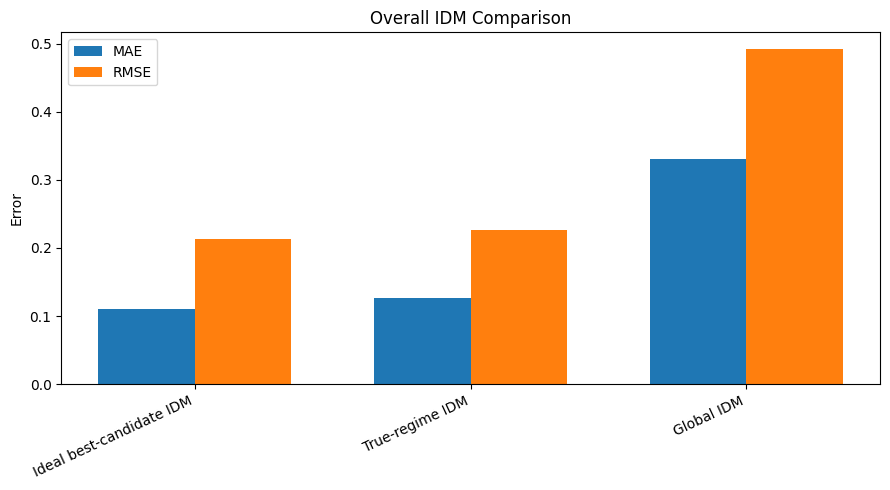

In [29]:
# ============================================================
# VISUAL 1: OVERALL IDM COMPARISON
# ============================================================

plot_df = idm_summary_df.sort_values("MAE").copy()

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(plot_df))
width = 0.35

ax.bar(x - width / 2, plot_df["MAE"], width, label="MAE")
ax.bar(x + width / 2, plot_df["RMSE"], width, label="RMSE")

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=25, ha="right")
ax.set_title("Overall IDM Comparison")
ax.set_ylabel("Error")
ax.legend()
plt.tight_layout()
plt.show()

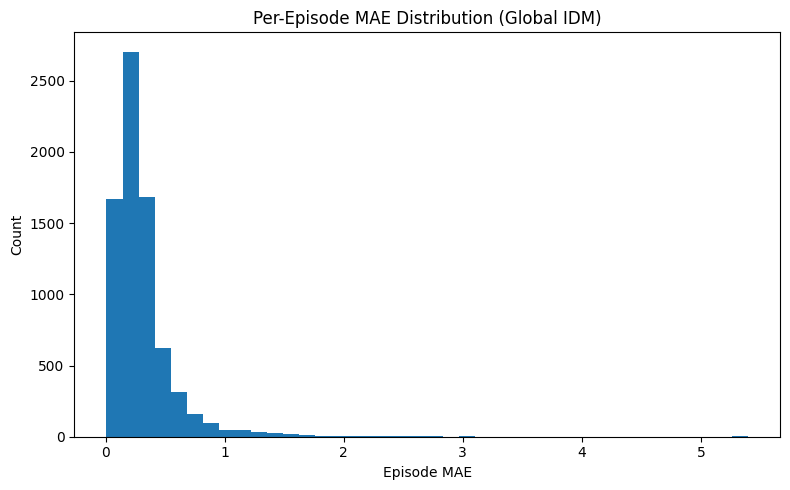

In [30]:
# ============================================================
# VISUAL 2: PER-EPISODE MAE DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(episode_metrics_test["mae"], bins=40)
ax.set_title("Per-Episode MAE Distribution (Global IDM)")
ax.set_xlabel("Episode MAE")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

In [31]:
# ============================================================
# SAVE FINAL IDM OUTPUTS
# Same folder, horizon-specific filenames
# ============================================================

idm_summary_df.to_csv(
    RUN_DIR / f"idm_final_summary_{HORIZON_TAG}.csv",
    index=False
)

metrics_df.to_csv(
    RUN_DIR / f"idm_global_split_metrics_{HORIZON_TAG}.csv",
    index=False
)

regime_metrics_test.to_csv(
    RUN_DIR / f"idm_global_regime_metrics_{HORIZON_TAG}.csv",
    index=False
)

ideal_piecewise_regime_metrics.to_csv(
    RUN_DIR / f"idm_true_regime_metrics_{HORIZON_TAG}.csv",
    index=False
)

best_candidate_regime_metrics.to_csv(
    RUN_DIR / f"idm_ideal_best_candidate_regime_metrics_{HORIZON_TAG}.csv",
    index=False
)

episode_metrics_test.to_csv(
    RUN_DIR / f"idm_global_episode_metrics_{HORIZON_TAG}.csv",
    index=False
)

# Save prediction files for secondary / horizon evaluation
global_pred_export = idm_test_global_scored.copy()
global_pred_export = global_pred_export.rename(columns={
    "a_true": "y_true",
    "a_idm": "y_pred"
})
global_pred_export["Model"] = "Global IDM"
global_pred_export["error"] = global_pred_export["y_pred"] - global_pred_export["y_true"]

global_pred_export.to_csv(
    RUN_DIR / f"global_idm_test_predictions_{HORIZON_TAG}.csv",
    index=False
)

true_regime_pred_export = idm_test_ideal_piecewise_scored.copy()
true_regime_pred_export = true_regime_pred_export.rename(columns={
    "a_true": "y_true",
    "a_idm_piecewise": "y_pred"
})
true_regime_pred_export["Model"] = "True-regime IDM"
true_regime_pred_export["error"] = (
    true_regime_pred_export["y_pred"] - true_regime_pred_export["y_true"]
)

true_regime_pred_export.to_csv(
    RUN_DIR / f"true_regime_idm_test_predictions_{HORIZON_TAG}.csv",
    index=False
)

# Optional compatibility copy for old notebooks
true_regime_pred_export.to_csv(
    RUN_DIR / f"oracle_regime_aware_idm_test_predictions_{HORIZON_TAG}.csv",
    index=False
)

best_candidate_pred_export = idm_test_best_candidate_scored.copy()
best_candidate_pred_export = best_candidate_pred_export.rename(columns={
    "a_true": "y_true",
    "a_idm_best_candidate": "y_pred"
})
best_candidate_pred_export["Model"] = "Ideal best-candidate IDM"
best_candidate_pred_export["error"] = (
    best_candidate_pred_export["y_pred"] - best_candidate_pred_export["y_true"]
)

best_candidate_pred_export.to_csv(
    RUN_DIR / f"ideal_best_candidate_idm_test_predictions_{HORIZON_TAG}.csv",
    index=False
)

with open(RUN_DIR / f"idm_core_config_{HORIZON_TAG}.json", "w") as f:
    json.dump({
        "BRAKE_THRESHOLD": BRAKE_THRESHOLD,
        "ACCEL_THRESHOLD": ACCEL_THRESHOLD,
        "FPS": FPS,
        "HISTORY": HISTORY,
        "HORIZON": HORIZON,
        "STRIDE": STRIDE,
        "HORIZON_SECONDS": HORIZON_SECONDS,
        "HORIZON_TAG": HORIZON_TAG,
        "best_global_params": best_global_params,
        "best_params_braking": best_params_braking,
        "best_params_accel": best_params_accel,
        "best_params_steady": best_params_steady,
    }, f, indent=2)

print("Saved IDM core outputs to:")
print(RUN_DIR)

print("\nSaved horizon-specific files with tag:")
print(HORIZON_TAG)

Saved IDM core outputs to:
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_brake0p1_accel0p2

Saved horizon-specific files with tag:
H25_Hz75_S1
